In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/wayanradityaputra/panoptic-indoor-segmentation-v5-coco-format/README.dataset.txt
/kaggle/input/datasets/wayanradityaputra/panoptic-indoor-segmentation-v5-coco-format/README.roboflow.txt
/kaggle/input/datasets/wayanradityaputra/panoptic-indoor-segmentation-v5-coco-format/test/001_jpg.rf.4e68c60b740dfb573ae743bc71df83e2.jpg
/kaggle/input/datasets/wayanradityaputra/panoptic-indoor-segmentation-v5-coco-format/test/002_jpg.rf.941b44d4633817fd833de04127e2f3a3.jpg
/kaggle/input/datasets/wayanradityaputra/panoptic-indoor-segmentation-v5-coco-format/test/003_jpg.rf.4bbaea88cef2fe3ec5e2f7d0af935f6a.jpg
/kaggle/input/datasets/wayanradityaputra/panoptic-indoor-segmentation-v5-coco-format/test/004_jpg.rf.403e439be69fbeb646bf7010aaf52ed0.jpg
/kaggle/input/datasets/wayanradityaputra/panoptic-indoor-segmentation-v5-coco-format/test/005_jpg.rf.f2248d837b7b97b5870fc8796a0eefd8.jpg
/kaggle/input/datasets/wayanradityaputra/panoptic-indoor-segmentation-v5-coco-format/test/006_jpg.rf.

In [2]:
# Install Dependencies

%pip install -q pycocotools

Note: you may need to restart the kernel to use updated packages.


In [3]:
# Imports and Configuration

import json
import time
import random
import shutil
from copy import deepcopy
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import torch
import torchvision
import matplotlib.pyplot as plt

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms.functional import to_tensor
from torchvision.models.detection import (
    maskrcnn_resnet50_fpn,
    MaskRCNN_ResNet50_FPN_Weights
)
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.mask_rcnn import MaskRCNNPredictor
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from pycocotools import mask as mask_utils

SEED = 42
NUM_OBJECT_CLASSES = 74
NUM_MODEL_CLASSES = 75

MAX_EPOCHS = 20
MAX_RUNTIME_MINUTES = 105
BATCH_SIZE = 2
LEARNING_RATE = 0.005

RUN_DIR = Path(
    "/kaggle/working/experiments/maskrcnn_all74_coco"
)
PREP_DIR = RUN_DIR / "corrected_annotations"
WEIGHTS_DIR = RUN_DIR / "weights"

for folder in [RUN_DIR, PREP_DIR, WEIGHTS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

assert torch.cuda.is_available(), "GPU is required"
DEVICE = torch.device("cuda:0")

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("GPU:", torch.cuda.get_device_name(0))
print("Training device:", DEVICE)

candidates = sorted(
    Path("/kaggle/input").rglob(
        "train/_annotations.coco.json"
    )
)

assert len(candidates) == 1, (
    "Expected exactly one COCO dataset. "
    f"Found: {candidates}"
)

COCO_ROOT = candidates[0].parent.parent

for split in ["train", "valid", "test"]:
    assert (
        COCO_ROOT / split / "_annotations.coco.json"
    ).is_file(), f"Missing COCO annotations: {split}"

print("COCO dataset:", COCO_ROOT)

PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
GPU: Tesla T4
Training device: cuda:0
COCO dataset: /kaggle/input/datasets/wayanradityaputra/panoptic-indoor-segmentation-v5-coco-format


In [4]:
# Repair COCO Annotation Geometry

ROTATION_FIXES = {
    "train": {
        "182169107": "CCW",
        "182169121": "CCW",
    },
    "valid": {
        "182169109": "CW",
        "182169108": "CCW",
    },
    "test": {}
}

def get_rotation(split, filename):
    matched = [
        direction
        for prefix, direction
        in ROTATION_FIXES[split].items()
        if filename.startswith(prefix + "_")
    ]

    assert len(matched) <= 1
    return matched[0] if matched else None


def rotate_polygon(polygon, original_width, original_height, direction):
    coords = np.asarray(
        polygon, dtype=np.float64
    ).reshape(-1, 2)

    x = coords[:, 0].copy()
    y = coords[:, 1].copy()

    if direction == "CW":
        coords[:, 0] = original_height - y
        coords[:, 1] = x

    elif direction == "CCW":
        coords[:, 0] = y
        coords[:, 1] = original_width - x

    else:
        raise ValueError(f"Unknown rotation: {direction}")

    return coords.reshape(-1).tolist()


corrected_json_paths = {}
repair_records = []

for split in ["train", "valid", "test"]:

    source_json = (
        COCO_ROOT / split / "_annotations.coco.json"
    )

    with open(source_json, "r") as f:
        data = json.load(f)

    data.setdefault("info", {})
    data.setdefault("licenses", [])

    categories = [
        category
        for category in data["categories"]
        if int(category["id"]) != 0
    ]

    category_ids = {
        int(category["id"])
        for category in categories
    }

    assert category_ids == set(range(1, 75)), (
        f"Unexpected category IDs in {split}"
    )

    data["categories"] = categories

    image_lookup = {}

    for image in data["images"]:
        filename = image["file_name"]
        image_path = COCO_ROOT / split / filename

        assert image_path.is_file(), image_path

        with Image.open(image_path) as img:
            actual_width, actual_height = img.size

        original_width = int(image["width"])
        original_height = int(image["height"])

        direction = get_rotation(split, filename)

        if direction is not None:
            assert (
                actual_width == original_height
                and actual_height == original_width
            ), f"Unexpected rotation dimensions: {filename}"

            repair_records.append({
                "split": split,
                "file_name": filename,
                "rotation": direction,
                "original_size": [
                    original_width,
                    original_height
                ],
                "actual_size": [
                    actual_width,
                    actual_height
                ]
            })

        else:
            assert (
                actual_width == original_width
                and actual_height == original_height
            ), f"Unrecognized dimension mismatch: {filename}"

        image["width"] = actual_width
        image["height"] = actual_height

        image_lookup[int(image["id"])] = {
            "original_width": original_width,
            "original_height": original_height,
            "actual_width": actual_width,
            "actual_height": actual_height,
            "rotation": direction
        }

    for annotation in data["annotations"]:

        category_id = int(annotation["category_id"])

        assert category_id in category_ids

        image_info = image_lookup[
            int(annotation["image_id"])
        ]

        polygons = annotation["segmentation"]

        assert (
            isinstance(polygons, list)
            and len(polygons) > 0
        ), "Expected polygon-based COCO annotations"

        corrected_polygons = []

        for polygon in polygons:
            if image_info["rotation"] is not None:
                polygon = rotate_polygon(
                    polygon,
                    image_info["original_width"],
                    image_info["original_height"],
                    image_info["rotation"]
                )

            coords = np.asarray(
                polygon, dtype=np.float64
            ).reshape(-1, 2)

            width = image_info["actual_width"]
            height = image_info["actual_height"]

            assert np.isfinite(coords).all()

            assert (
                (coords[:, 0] >= -1e-4).all()
                and (coords[:, 0] <= width + 1e-4).all()
                and (coords[:, 1] >= -1e-4).all()
                and (coords[:, 1] <= height + 1e-4).all()
            ), "Polygon outside image bounds"

            corrected_polygons.append(polygon)

        annotation["segmentation"] = corrected_polygons

        height = image_info["actual_height"]
        width = image_info["actual_width"]

        rles = mask_utils.frPyObjects(
            corrected_polygons,
            height,
            width
        )
        rle = mask_utils.merge(rles)

        area = float(mask_utils.area(rle))
        bbox = mask_utils.toBbox(rle).tolist()

        assert area > 0, (
            f"Zero-area annotation: {annotation['id']}"
        )

        annotation["area"] = area
        annotation["bbox"] = [
            float(value) for value in bbox
        ]
        annotation["iscrowd"] = 0

    output_json = (
        PREP_DIR / f"{split}_corrected.json"
    )

    with open(output_json, "w") as f:
        json.dump(data, f)

    corrected_json_paths[split] = output_json

    print(
        split,
        "| images:", len(data["images"]),
        "| annotations:", len(data["annotations"])
    )


# Verify Dataset Repair

assert len(repair_records) == 4, (
    f"Expected four orientation repairs, "
    f"found {len(repair_records)}"
)

with open(PREP_DIR / "repair_manifest.json", "w") as f:
    json.dump(repair_records, f, indent=2)

print("\nOrientation repairs:")
for item in repair_records:
    print(
        item["split"],
        item["file_name"],
        item["rotation"]
    )

print("\nCOCO annotation preparation complete")

train | images: 397 | annotations: 4479
valid | images: 166 | annotations: 2022
test | images: 359 | annotations: 5344

Orientation repairs:
train 182169107_jpg.rf.c9b1bbecf1474a5b36a6df197c30dfed.jpg CCW
train 182169121_jpg.rf.eb0ccb71d0ea38adf1e38bf9c02a4a15.jpg CCW
valid 182169109_jpg.rf.0531e60eb6e404d9633ed0c23a381fe7.jpg CW
valid 182169108_jpg.rf.205d9f1ed8f888006b8f97fc29eb8790.jpg CCW

COCO annotation preparation complete


loading annotations into memory...
Done (t=0.04s)
creating index...
index created!
loading annotations into memory...
Done (t=0.02s)
creating index...
index created!
Train images: 397
Validation images: 166
Image shape: (3, 480, 640)
Instances in sample: 11


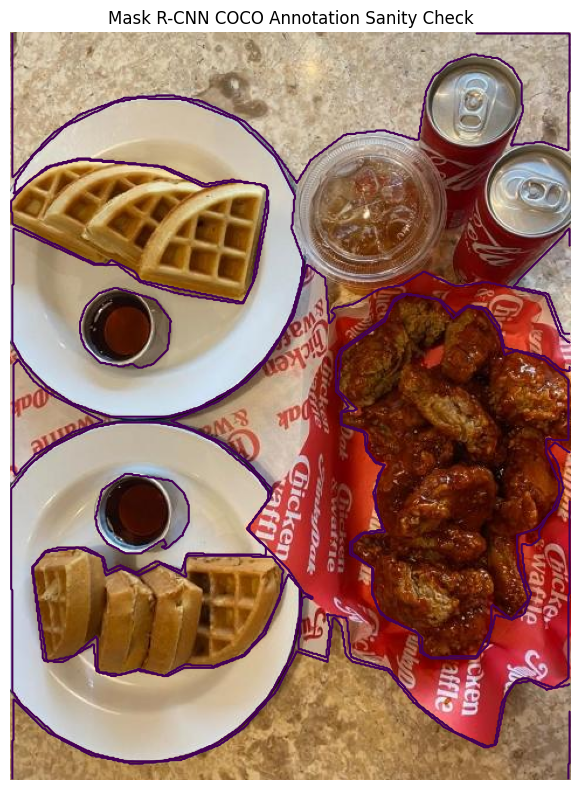

In [5]:
# COCO Instance Segmentation Dataset

class IndoorCOCODataset(Dataset):

    def __init__(self, image_dir, annotation_file):
        self.image_dir = Path(image_dir)
        self.coco = COCO(str(annotation_file))
        self.ids = sorted(self.coco.getImgIds())

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, index):

        image_id = self.ids[index]
        image_info = self.coco.loadImgs(
            [image_id]
        )[0]

        image_path = (
            self.image_dir / image_info["file_name"]
        )

        with Image.open(image_path) as img:
            image = img.convert("RGB")

        width, height = image.size

        annotation_ids = self.coco.getAnnIds(
            imgIds=[image_id],
            iscrowd=False
        )

        annotations = self.coco.loadAnns(
            annotation_ids
        )

        boxes = []
        labels = []
        masks = []
        areas = []

        for annotation in annotations:
            x, y, w, h = annotation["bbox"]

            if w <= 0 or h <= 0:
                raise ValueError(
                    f"Invalid bbox: {annotation['id']}"
                )

            boxes.append([
                x, y, x + w, y + h
            ])

            labels.append(
                int(annotation["category_id"])
            )

            masks.append(
                self.coco.annToMask(annotation)
            )

            areas.append(
                float(annotation["area"])
            )

        if boxes:
            boxes = torch.tensor(
                boxes, dtype=torch.float32
            )
            labels = torch.tensor(
                labels, dtype=torch.int64
            )
            masks = torch.tensor(
                np.stack(masks),
                dtype=torch.uint8
            )
            areas = torch.tensor(
                areas, dtype=torch.float32
            )
        else:
            boxes = torch.zeros(
                (0, 4), dtype=torch.float32
            )
            labels = torch.zeros(
                (0,), dtype=torch.int64
            )
            masks = torch.zeros(
                (0, height, width),
                dtype=torch.uint8
            )
            areas = torch.zeros(
                (0,), dtype=torch.float32
            )

        target = {
            "boxes": boxes,
            "labels": labels,
            "masks": masks,
            "image_id": torch.tensor(
                image_id, dtype=torch.int64
            ),
            "area": areas,
            "iscrowd": torch.zeros(
                len(labels), dtype=torch.int64
            )
        }

        return to_tensor(image), target


def collate_fn(batch):
    return tuple(zip(*batch))


train_dataset = IndoorCOCODataset(
    COCO_ROOT / "train",
    corrected_json_paths["train"]
)

val_dataset = IndoorCOCODataset(
    COCO_ROOT / "valid",
    corrected_json_paths["valid"]
)

assert len(train_dataset) == 397
assert len(val_dataset) == 166

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    collate_fn=collate_fn
)

val_loader = DataLoader(
    val_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
    collate_fn=collate_fn
)


# Verify One Sample

image, target = train_dataset[0]

assert image.shape[0] == 3
assert target["boxes"].shape[1] == 4
assert target["masks"].shape[0] == len(
    target["labels"]
)

assert (
    (target["labels"] >= 1).all()
    and (target["labels"] <= 74).all()
)

print("Train images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Image shape:", tuple(image.shape))
print("Instances in sample:", len(target["labels"]))


# Inspect Repaired Validation Image

repaired_val_id = 8

assert repaired_val_id in val_dataset.ids

sample_index = val_dataset.ids.index(
    repaired_val_id
)

sample_image, sample_target = val_dataset[
    sample_index
]

plt.figure(figsize=(8, 8))
plt.imshow(
    sample_image.permute(1, 2, 0).numpy()
)

for mask in sample_target["masks"][:12]:
    plt.contour(
        mask.numpy(),
        levels=[0.5],
        linewidths=1.5
    )

plt.title("Mask R-CNN COCO Annotation Sanity Check")
plt.axis("off")
plt.tight_layout()

plt.savefig(
    RUN_DIR / "annotation_sanity_check.png",
    dpi=150
)

plt.show()

In [6]:
# Initialize Mask R-CNN

weights = MaskRCNN_ResNet50_FPN_Weights.DEFAULT

model = maskrcnn_resnet50_fpn(
    weights=weights,
    min_size=640,
    max_size=960,
    box_detections_per_img=100
)

# Replace Classification and Bounding Box Head

box_features = (
    model.roi_heads.box_predictor.cls_score.in_features
)

model.roi_heads.box_predictor = FastRCNNPredictor(
    box_features,
    NUM_MODEL_CLASSES
)

# Replace Segmentation Mask Head

mask_features = (
    model.roi_heads.mask_predictor.conv5_mask.in_channels
)

model.roi_heads.mask_predictor = MaskRCNNPredictor(
    mask_features,
    256,
    NUM_MODEL_CLASSES
)

model = model.to(DEVICE)

optimizer = torch.optim.SGD(
    [p for p in model.parameters() if p.requires_grad],
    lr=LEARNING_RATE,
    momentum=0.9,
    weight_decay=0.0005
)

scheduler = torch.optim.lr_scheduler.MultiStepLR(
    optimizer,
    milestones=[10, 15],
    gamma=0.1
)

USE_AMP = True

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=USE_AMP
)

config = {
    "experiment": "maskrcnn_all74_coco",
    "architecture": "Mask R-CNN ResNet-50 FPN",
    "pretrained": "Torchvision COCO pretrained",
    "object_classes": NUM_OBJECT_CLASSES,
    "model_classes_including_background": NUM_MODEL_CLASSES,
    "train_images": len(train_dataset),
    "validation_images": len(val_dataset),
    "max_epochs": MAX_EPOCHS,
    "max_runtime_minutes": MAX_RUNTIME_MINUTES,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "optimizer": "SGD",
    "momentum": 0.9,
    "weight_decay": 0.0005,
    "scheduler_milestones": [10, 15],
    "image_min_size": 640,
    "image_max_size": 960,
    "seed": SEED,
    "gpu": torch.cuda.get_device_name(0),
    "device": "cuda:0",
    "amp_enabled": USE_AMP,
    "torch_version": torch.__version__,
    "torchvision_version": torchvision.__version__,
    "validation_protocol": "COCOeval bbox and segm",
    "test_set_evaluated": False
}

with open(RUN_DIR / "config.json", "w") as f:
    json.dump(config, f, indent=2)

print("Model initialized successfully")
print("Object classes:", NUM_OBJECT_CLASSES)
print("Model classes:", NUM_MODEL_CLASSES)
print("GPU:", config["gpu"])

Downloading: "https://download.pytorch.org/models/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth" to /root/.cache/torch/hub/checkpoints/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth


100%|██████████| 170M/170M [00:00<00:00, 187MB/s]


Model initialized successfully
Object classes: 74
Model classes: 75
GPU: Tesla T4


In [7]:
# COCO Validation Evaluation

import io
from contextlib import redirect_stdout


def make_detection_coco(coco_gt, predictions):

    if predictions:
        return coco_gt.loadRes(predictions)

    empty = COCO()
    empty.dataset = {
        "info": deepcopy(
            coco_gt.dataset.get("info", {})
        ),
        "images": deepcopy(
            coco_gt.dataset["images"]
        ),
        "categories": deepcopy(
            coco_gt.dataset["categories"]
        ),
        "annotations": []
    }
    empty.createIndex()
    return empty


def evaluate_coco_records(coco_gt, predictions, iou_type):

    with redirect_stdout(io.StringIO()):

        coco_dt = make_detection_coco(
            coco_gt,
            predictions
        )

        evaluator = COCOeval(
            coco_gt,
            coco_dt,
            iouType=iou_type
        )

        evaluator.params.imgIds = sorted(
            coco_gt.getImgIds()
        )

        evaluator.evaluate()
        evaluator.accumulate()
        evaluator.summarize()

    return evaluator


@torch.inference_mode()
def validate_model(model, loader, coco_gt):

    model.eval()

    bbox_predictions = []
    mask_predictions = []

    for images, targets in loader:

        images = [
            image.to(DEVICE)
            for image in images
        ]

        outputs = model(images)

        for output, target in zip(outputs, targets):

            image_id = int(
                target["image_id"].item()
            )

            boxes = output["boxes"].cpu().numpy()
            labels = output["labels"].cpu().numpy()
            scores = output["scores"].cpu().numpy()
            masks = output["masks"].cpu().numpy()

            for box, label, score, mask in zip(
                boxes, labels, scores, masks
            ):

                x1, y1, x2, y2 = map(float, box)

                width = x2 - x1
                height = y2 - y1

                if width <= 0 or height <= 0:
                    continue

                category_id = int(label)

                if not 1 <= category_id <= 74:
                    continue

                common = {
                    "image_id": image_id,
                    "category_id": category_id,
                    "score": float(score)
                }

                bbox_predictions.append({
                    **common,
                    "bbox": [
                        x1, y1, width, height
                    ]
                })

                binary_mask = (
                    mask[0] >= 0.5
                ).astype(np.uint8)

                if not binary_mask.any():
                    continue

                rle = mask_utils.encode(
                    np.asfortranarray(binary_mask)
                )

                rle["counts"] = (
                    rle["counts"].decode("ascii")
                )

                mask_predictions.append({
                    **common,
                    "segmentation": rle
                })

    box_eval = evaluate_coco_records(
        coco_gt,
        bbox_predictions,
        "bbox"
    )

    mask_eval = evaluate_coco_records(
        coco_gt,
        mask_predictions,
        "segm"
    )

    metrics = {
        "box_map50_95": float(box_eval.stats[0]),
        "box_map50": float(box_eval.stats[1]),
        "mask_map50_95": float(mask_eval.stats[0]),
        "mask_map50": float(mask_eval.stats[1])
    }

    return metrics, mask_eval


def extract_per_class_mask_ap(
    evaluator,
    train_dataset,
    val_dataset
):

    precision = evaluator.eval["precision"]

    category_ids = evaluator.params.catIds

    train_counts = Counter(
        ann["category_id"]
        for ann in train_dataset.coco.dataset["annotations"]
    )

    val_counts = Counter(
        ann["category_id"]
        for ann in val_dataset.coco.dataset["annotations"]
    )

    records = []

    for index, category_id in enumerate(category_ids):

        values = precision[
            :, :, index, 0, -1
        ]

        valid_values = values[values > -1]

        ap = (
            float(valid_values.mean())
            if len(valid_values) > 0
            else np.nan
        )

        category_name = (
            val_dataset.coco.cats[category_id]["name"]
        )

        records.append({
            "category_id": int(category_id),
            "class_name": category_name,
            "train_instances": int(
                train_counts[category_id]
            ),
            "validation_instances": int(
                val_counts[category_id]
            ),
            "mask_ap50_95": ap
        })

    return pd.DataFrame(records)

In [8]:
# Train and Validate Mask R-CNN

LOSS_KEYS = [
    "loss_classifier",
    "loss_box_reg",
    "loss_mask",
    "loss_objectness",
    "loss_rpn_box_reg"
]

history = []
best_mask_map = -1.0
best_epoch = None
best_metrics = None

experiment_start = time.perf_counter()

for epoch in range(1, MAX_EPOCHS + 1):

    elapsed_minutes = (
        time.perf_counter() - experiment_start
    ) / 60

    if epoch > 1 and elapsed_minutes >= MAX_RUNTIME_MINUTES:
        print("Runtime budget reached. Stopping before next epoch.")
        break

    model.train()

    lr_at_epoch = optimizer.param_groups[0]["lr"]

    loss_totals = {
        name: 0.0
        for name in LOSS_KEYS
    }

    batch_count = 0

    torch.cuda.synchronize()
    train_start = time.perf_counter()

    for images, targets in train_loader:

        images = [
            image.to(DEVICE, non_blocking=True)
            for image in images
        ]

        targets = [
            {
                key: value.to(
                    DEVICE,
                    non_blocking=True
                )
                for key, value in target.items()
            }
            for target in targets
        ]

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=USE_AMP
        ):
            loss_dict = model(images, targets)
            total_loss = sum(loss_dict.values())

        if not torch.isfinite(total_loss).item():
            raise RuntimeError(
                f"Non-finite loss at epoch {epoch}"
            )

        scaler.scale(total_loss).backward()
        scaler.step(optimizer)
        scaler.update()

        values = torch.stack([
            loss_dict[name].detach().float()
            for name in LOSS_KEYS
        ]).cpu().numpy()

        for name, value in zip(LOSS_KEYS, values):
            loss_totals[name] += float(value)

        batch_count += 1

    torch.cuda.synchronize()

    train_seconds = (
        time.perf_counter() - train_start
    )


    # Validation

    val_start = time.perf_counter()

    metrics, mask_evaluator = validate_model(
        model,
        val_loader,
        val_dataset.coco
    )

    torch.cuda.synchronize()

    val_seconds = (
        time.perf_counter() - val_start
    )

    mean_losses = {
        name: loss_totals[name] / batch_count
        for name in LOSS_KEYS
    }

    mean_total_loss = sum(
        mean_losses.values()
    )

    elapsed_seconds = (
        time.perf_counter() - experiment_start
    )

    row = {
        "epoch": epoch,
        "time": elapsed_seconds,
        "train_seconds": train_seconds,
        "validation_seconds": val_seconds,
        "learning_rate": lr_at_epoch,
        "train_total_loss": mean_total_loss,
        **mean_losses,
        **metrics
    }

    history.append(row)

    pd.DataFrame(history).to_csv(
        RUN_DIR / "results.csv",
        index=False
    )


    # Best Checkpoint

    current_mask_map = metrics["mask_map50_95"]

    if current_mask_map > best_mask_map:

        best_mask_map = current_mask_map
        best_epoch = epoch
        best_metrics = metrics.copy()

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "validation_metrics": metrics,
                "config": config
            },
            WEIGHTS_DIR / "best.pth"
        )

        per_class_df = extract_per_class_mask_ap(
            mask_evaluator,
            train_dataset,
            val_dataset
        )

        per_class_df.to_csv(
            RUN_DIR / "per_class_val_ap.csv",
            index=False
        )


    # Last Checkpoint

    scheduler.step()

    torch.save(
        {
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "scaler_state_dict": scaler.state_dict(),
            "validation_metrics": metrics,
            "config": config
        },
        WEIGHTS_DIR / "last.pth"
    )

    print(
        f"Epoch {epoch}/{MAX_EPOCHS} | "
        f"Train Loss: {mean_total_loss:.4f} | "
        f"Mask mAP50-95: {current_mask_map:.4f} | "
        f"Best: {best_mask_map:.4f} | "
        f"Train: {train_seconds / 60:.1f} min | "
        f"Val: {val_seconds / 60:.1f} min"
    )


print("\nTRAINING COMPLETE")
print("Epochs recorded:", len(history))
print("Best epoch:", best_epoch)
print("Best validation mask mAP:", best_mask_map)

Epoch 1/20 | Train Loss: 2.3071 | Mask mAP50-95: 0.0389 | Best: 0.0389 | Train: 1.2 min | Val: 0.9 min
Epoch 2/20 | Train Loss: 1.6643 | Mask mAP50-95: 0.0676 | Best: 0.0676 | Train: 1.2 min | Val: 0.9 min
Epoch 3/20 | Train Loss: 1.3960 | Mask mAP50-95: 0.0726 | Best: 0.0726 | Train: 1.2 min | Val: 0.8 min
Epoch 4/20 | Train Loss: 1.2078 | Mask mAP50-95: 0.0782 | Best: 0.0782 | Train: 1.2 min | Val: 0.9 min
Epoch 5/20 | Train Loss: 1.0850 | Mask mAP50-95: 0.0869 | Best: 0.0869 | Train: 1.2 min | Val: 0.8 min
Epoch 6/20 | Train Loss: 0.9744 | Mask mAP50-95: 0.0874 | Best: 0.0874 | Train: 1.2 min | Val: 0.9 min
Epoch 7/20 | Train Loss: 0.8750 | Mask mAP50-95: 0.1019 | Best: 0.1019 | Train: 1.2 min | Val: 0.8 min
Epoch 8/20 | Train Loss: 0.7882 | Mask mAP50-95: 0.1076 | Best: 0.1076 | Train: 1.2 min | Val: 0.7 min
Epoch 9/20 | Train Loss: 0.7229 | Mask mAP50-95: 0.1247 | Best: 0.1247 | Train: 1.2 min | Val: 0.7 min
Epoch 10/20 | Train Loss: 0.6774 | Mask mAP50-95: 0.1276 | Best: 0.1276 |

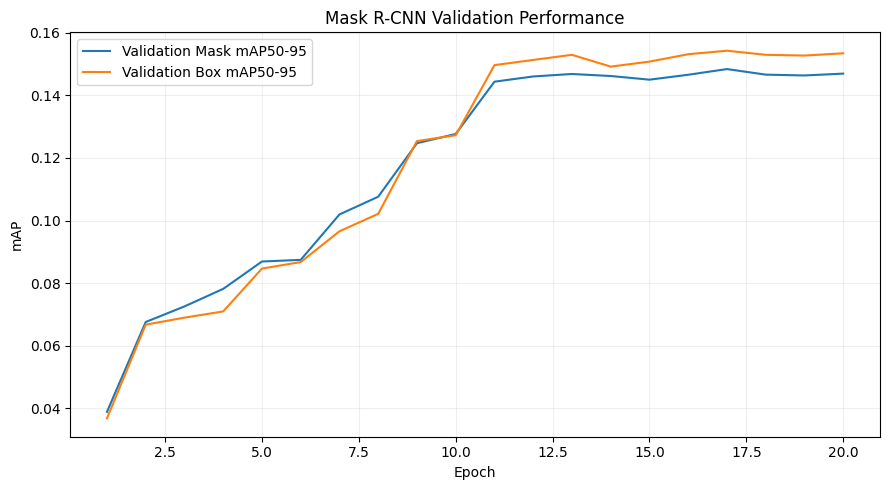


EXPERIMENT SUMMARY
{
  "experiment": "maskrcnn_all74_coco",
  "architecture": "Mask R-CNN ResNet-50 FPN",
  "num_object_classes": 74,
  "background_class": 0,
  "gpu": "Tesla T4",
  "gpu_count_used": 1,
  "configured_max_epochs": 20,
  "epochs_completed": 20,
  "best_epoch": 17,
  "best_validation_metrics": {
    "box_map50_95": 0.15424673666296695,
    "box_map50": 0.24088024219741896,
    "mask_map50_95": 0.14838387915459095,
    "mask_map50": 0.222464096126127
  },
  "recorded_training_and_validation_seconds": 2238.738107909,
  "recorded_training_and_validation_minutes": 37.31230179848333,
  "selection_metric": "validation mask mAP50-95",
  "test_set_evaluated": false,
  "checkpoint_best": "weights/best.pth",
  "checkpoint_last": "weights/last.pth"
}

EXPORT FILES
Results CSV: /kaggle/working/experiments/maskrcnn_all74_coco/results.csv
Per-class AP: /kaggle/working/experiments/maskrcnn_all74_coco/per_class_val_ap.csv
Best checkpoint: /kaggle/working/experiments/maskrcnn_all74_coco/

In [9]:
# Export Mask R-CNN Experiment Results

assert history, "No training history recorded"
assert (WEIGHTS_DIR / "best.pth").is_file()
assert (WEIGHTS_DIR / "last.pth").is_file()

results_df = pd.read_csv(
    RUN_DIR / "results.csv"
)

total_seconds = float(
    results_df["time"].iloc[-1]
)

summary = {
    "experiment": "maskrcnn_all74_coco",
    "architecture": "Mask R-CNN ResNet-50 FPN",
    "num_object_classes": 74,
    "background_class": 0,
    "gpu": torch.cuda.get_device_name(0),
    "gpu_count_used": 1,
    "configured_max_epochs": MAX_EPOCHS,
    "epochs_completed": len(results_df),
    "best_epoch": best_epoch,
    "best_validation_metrics": best_metrics,
    "recorded_training_and_validation_seconds": total_seconds,
    "recorded_training_and_validation_minutes": total_seconds / 60,
    "selection_metric": "validation mask mAP50-95",
    "test_set_evaluated": False,
    "checkpoint_best": "weights/best.pth",
    "checkpoint_last": "weights/last.pth"
}

with open(RUN_DIR / "summary.json", "w") as f:
    json.dump(summary, f, indent=2)


# Plot Training and Validation Metrics

plt.figure(figsize=(9, 5))

plt.plot(
    results_df["epoch"],
    results_df["mask_map50_95"],
    label="Validation Mask mAP50-95"
)

plt.plot(
    results_df["epoch"],
    results_df["box_map50_95"],
    label="Validation Box mAP50-95"
)

plt.xlabel("Epoch")
plt.ylabel("mAP")
plt.title("Mask R-CNN Validation Performance")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    RUN_DIR / "validation_metrics.png",
    dpi=150
)

plt.show()


# Package Outputs

zip_path = shutil.make_archive(
    "/kaggle/working/maskrcnn_all74_outputs",
    "zip",
    root_dir=str(RUN_DIR.parent),
    base_dir=RUN_DIR.name
)

print("\nEXPERIMENT SUMMARY")
print(json.dumps(summary, indent=2))

print("\nEXPORT FILES")
print("Results CSV:", RUN_DIR / "results.csv")
print("Per-class AP:", RUN_DIR / "per_class_val_ap.csv")
print("Best checkpoint:", WEIGHTS_DIR / "best.pth")
print("Last checkpoint:", WEIGHTS_DIR / "last.pth")
print("ZIP:", zip_path)

print("\nMASK R-CNN PIPELINE COMPLETE")